In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("Online Retail.xlsx")

# Keep valid sales records for this analysis
retail = df.drop_duplicates().copy()
retail = retail.dropna(subset=["StockCode", "InvoiceDate"])
retail = retail[
    (retail["Quantity"] > 0) &
    (retail["UnitPrice"] > 0)
].copy()

retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"])
retail["Revenue"] = retail["Quantity"] * retail["UnitPrice"]
retail["Month"] = retail["InvoiceDate"].dt.to_period("M").astype(str)

print("Rows available for analysis:", len(retail))
display(retail.head())

Rows available for analysis: 524878


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [3]:
product_month = (
    retail.groupby(["StockCode", "Month"], as_index=False)
    .agg(
        Average_Price=("UnitPrice", "mean"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Transaction_Count=("InvoiceNo", "nunique")
    )
)

print("Product-month records:", len(product_month))
display(product_month.head(10))

Product-month records: 34069


,StockCode,Month,Average_Price,Total_Quantity,Total_Revenue,Transaction_Count
0,10002,2010-12,1.201000,251,234.41,30
1,10002,2011-01,0.962857,340,291.37,21
2,10002,2011-02,1.072857,52,45.76,7
3,10002,2011-03,1.142500,28,27.70,8
4,10002,2011-04,0.850000,189,160.65,5
5,10080,2011-02,0.850000,2,1.70,1
6,10080,2011-06,0.390000,60,23.40,2
7,10080,2011-07,0.390000,24,9.36,2
8,10080,2011-08,0.390000,60,23.40,4
9,10080,2011-09,0.390000,60,23.40,4


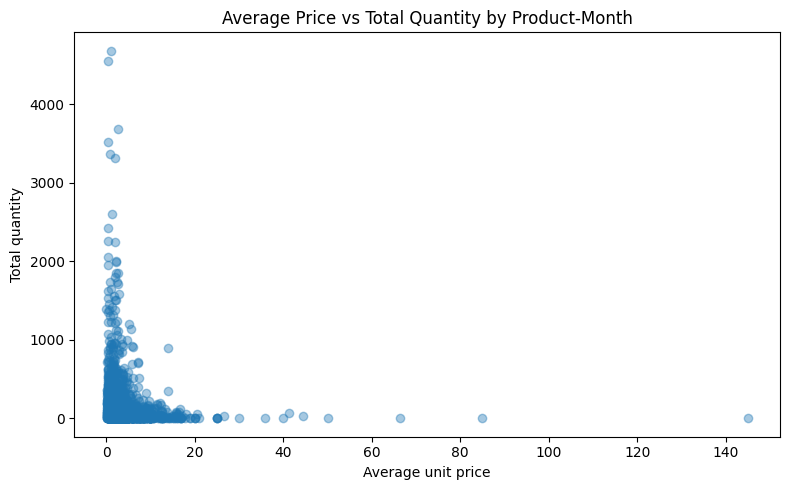

In [4]:
sample = product_month.sample(
    n=min(2000, len(product_month)),
    random_state=42
)

plt.figure(figsize=(8, 5))
plt.scatter(
    sample["Average_Price"],
    sample["Total_Quantity"],
    alpha=0.4
)
plt.title("Average Price vs Total Quantity by Product-Month")
plt.xlabel("Average unit price")
plt.ylabel("Total quantity")
plt.tight_layout()
plt.show()

# Analysis Summary & Observations

- **Number of Product-Month Records**: There are **34,069** product-month records created after grouping the data.
- **Price vs. Quantity Pattern**: The scatter plot shows a classic downward-sloping curve indicating a potential power-law or inverse relationship. Products with lower average unit prices (specifically under $20) tend to have much higher total quantities sold. As the average unit price increases, the maximum volume of transactions and quantity drops significantly.
- **Unusual Records to Investigate**:
  - **High-Quantity Outliers**: There are a few records with low prices (under $5) but extremely high monthly volumes exceeding 3,000 to 4,500 units.
  - **High-Price Outliers**: There is at least one transaction where the average unit price is exceptionally high (around $145), yet the total quantity purchased is very close to zero. This could represent specialized items, samples, or manual adjustments.
- **Limitation**: This relationship is purely descriptive and represents historical correlations. It does not provide causal proof that changing prices directly causes a change in demand, as other confounding factors (seasonality, product categories, promotions, etc.) are not controlled for.